# Multiple Linear Regression — House Prices

**Goal:** predict a house's price from **two** features at the same time: size (sq ft) and number of bedrooms.

With more than one feature, the model is `price = b + w1·size + w2·bedrooms`. The weights `w` form a vector, one per feature.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Load data from the CSV file
df = pd.read_csv('/content/sample_data/house_price.csv')

# 2. Separate independent variables (X) and dependent variable (y)
# Here, X represents our vector parameter inputs
X = df[['Size_sqft', 'Bedrooms']]
y = df['Price_USD']

# 3. Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Initialize and fit the Multiple Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# 5. Make predictions
y_pred = model.predict(X_test)

# 6. Extract the Vector Parameters (Weights/Coefficients)
print(f"Intercept (b): {model.intercept_:.2f}")
print(f"Coefficients / Weights Vector (w): {model.coef_}")

# 7. Evaluate the Model
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.2f}")
print(f"R-squared Score (R²): {r2_score(y_test, y_pred):.2f}")

Intercept (b): 22512.06
Coefficients / Weights Vector (w): [  194.05144695 -4308.68167203]
Mean Squared Error (MSE): 5631613.74
R-squared Score (R²): 1.00


## Reading the results
- **Size coefficient ≈ +194:** each extra sq ft adds about $194, *with the number of bedrooms held constant*.
- **Bedroom coefficient ≈ −4,309:** this looked strange at first. It means that for a house of the **same size**, one extra bedroom makes the rooms smaller, so the price is a bit lower.
- **R² = 1.00** with a very small error: the model almost perfectly fits this small dataset. Real house data would be much noisier, so a score this high usually means the dataset is small or very clean.
- I split the data 80/20 so the score comes from houses the model **didn't** see during training.

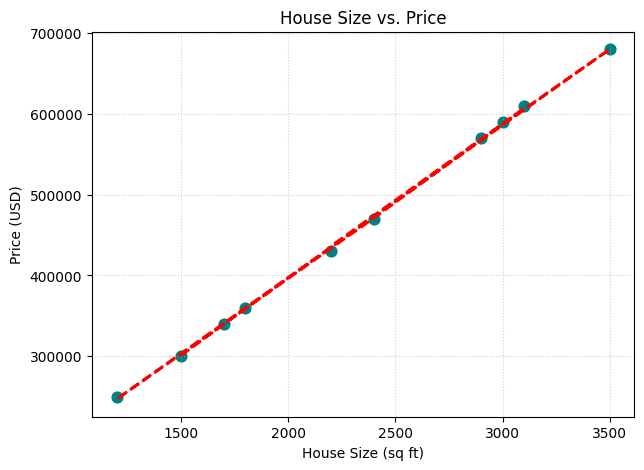

In [ ]:
import matplotlib.pyplot as plt

# Create figure canvas
plt.figure(figsize=(7, 5))

# Plot Size vs Price points from your dataset
plt.scatter(df['Size_sqft'], df['Price_USD'], color='teal', alpha=1, s=60)

# Plot trend line
# Trend line using model predictions across the dataset
plt.plot(df['Size_sqft'], model.predict(X), color='red', linestyle='--', linewidth=2, label='Trend Line')
# plt.plot(df['Size_sqft'], m * df['Size_sqft'] + c, color='red', linestyle='--', linewidth=2, label='Trend Line')

# Labels and title
plt.xlabel('House Size (sq ft)')
plt.ylabel('Price (USD)')
plt.title('House Size vs. Price')
plt.grid(True, linestyle=':', alpha=0.6)

# Render plot
plt.show()

The red dashed line shows the model's predictions plotted against size.

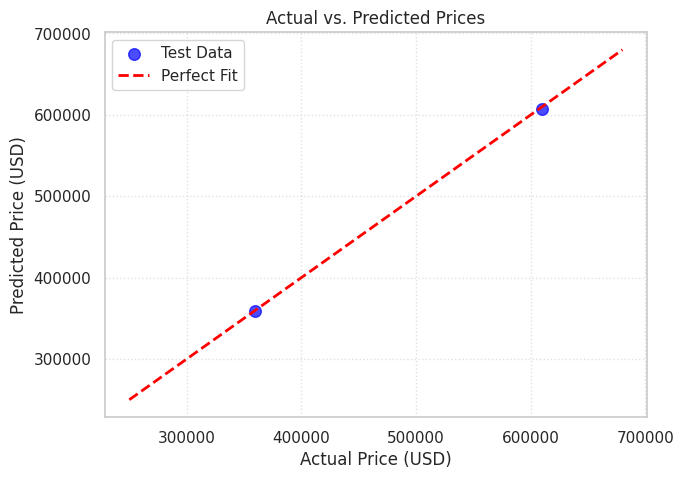

In [ ]:
import matplotlib.pyplot as plt

# Create the figure and axis
plt.figure(figsize=(7, 5))

# Scatter plot of actual vs. predicted values
plt.scatter(y_test, y_pred, color='blue', label='Test Data', alpha=0.7, s=70)

# Reference line for a perfect model fit (y = y_pred)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', linestyle='--', linewidth=2, label='Perfect Fit')

# Labels and title
plt.xlabel('Actual Price (USD)')
plt.ylabel('Predicted Price (USD)')
plt.title('Actual vs. Predicted Prices')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

# Render plot
plt.show()

**Actual vs predicted:** if the model were perfect, every point would sit on the red diagonal line. Points far from the line are the biggest errors.